# Assignment 6 · Urban Fashion Campaign Analytics

**Arafat Mahmood**  
**INFO57086 · Social Media Data Mining & Analysis**

## Table of contents

1. [Dataset](#1.-Dataset)
2. [Audience analytics](#2.-Audience-analytics)
3. [Text analytics](#3.-Text-analytics)
4. [Location analytics](#4.-Location-analytics)
5. [Network analytics](#5.-Network-analytics)
6. [Integration and recommendations](#6.-Integration-and-recommendations)

## 1. Dataset

I created a synthetic sample of 12 customer posts about Urban Fashion's October 2026 campaign. Each user contributes one post. The sample covers Instagram, Facebook, TikTok, and X, with images and videos from three GTA cities. The dataset is embedded below so the notebook can run without a separate download. All fields are populated and already in the required format.

I chose this dataset because a single user ID connects the post, audience metrics, city, and community to that user's interactions. That makes it possible to check whether highly engaged posts also come from positive, well-connected users. The counts and captions are fictional, so the results describe the exercise dataset.

| Field | Meaning                                                                                                      |
| --- |--------------------------------------------------------------------------------------------------------------|
| PostID | Unique identifier for each post                                                                              |
| User | Account that published the post                                                                              |
| Date | Date the post appeared during the campaign                                                                   |
| Platform | Social media platform                                                                                        |
| Media | Image or video                                                                                               |
| Post | Text of the customer's campaign post                                                                         |
| City | City associated with the post                                                                                |
| Community | Interest group assigned to the account                                                                       |
| Reach | Number of accounts reached by the post                                                                       |
| Likes, Comments, Shares | Counts of interactions received by the post                                                                  |
| Source, Target | Two users in a separate interaction table. Each pair represents one recorded campaign discussion connection. |

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

posts = pd.DataFrame([
    ('P01', 'Maya', '2026-10-02', 'TikTok', 'Video', 'Love the streetwear launch. Great hoodie!', 'Mississauga', 'Streetwear', 1200, 150, 35, 25),
    ('P02', 'Omar', '2026-10-04', 'Instagram', 'Video', 'Great colours and love the relaxed fit.', 'Mississauga', 'Streetwear', 1000, 110, 25, 15),
    ('P03', 'Ava', '2026-10-06', 'Facebook', 'Image', 'The campaign runs until the end of October.', 'Mississauga', 'Everyday Style', 1100, 89, 21, 10),
    ('P04', 'Liam', '2026-10-08', 'X', 'Image', 'Disappointed that my size was unavailable.', 'Mississauga', 'Budget Finds', 800, 68, 17, 5),
    ('P05', 'Zoe', '2026-10-10', 'Instagram', 'Video', 'Love the styling ideas. Excellent campaign!', 'Toronto', 'Everyday Style', 2000, 170, 40, 30),
    ('P06', 'Noah', '2026-10-12', 'TikTok', 'Video', 'Great outfit ideas for fall.', 'Toronto', 'Everyday Style', 1550, 95, 23, 12),
    ('P07', 'Isla', '2026-10-14', 'Facebook', 'Image', 'Love the prices on the campaign jackets.', 'Toronto', 'Budget Finds', 1350, 82, 20, 8),
    ('P08', 'Ethan', '2026-10-16', 'X', 'Image', 'Frustrated that the advertised size was unavailable.', 'Toronto', 'Streetwear', 1000, 50, 17, 3),
    ('P09', 'Nina', '2026-10-19', 'Instagram', 'Image', 'Awful delivery experience. My order arrived late.', 'Oakville', 'Budget Finds', 750, 76, 31, 8),
    ('P10', 'Kai', '2026-10-22', 'TikTok', 'Video', 'Great deal on the new campaign sneakers.', 'Oakville', 'Budget Finds', 650, 60, 15, 10),
    ('P11', 'Sofia', '2026-10-25', 'Facebook', 'Image', 'Love the jacket in the fall collection.', 'Oakville', 'Streetwear', 700, 53, 13, 4),
    ('P12', 'Leo', '2026-10-28', 'X', 'Image', 'The collection is listed on the website.', 'Oakville', 'Everyday Style', 500, 37, 10, 3)
], columns=[
    'PostID', 'User', 'Date', 'Platform', 'Media', 'Post', 'City', 'Community',
    'Reach', 'Likes', 'Comments', 'Shares'
])

display(posts)


,PostID,User,Date,Platform,Media,Post,City,Community,Reach,Likes,Comments,Shares
0,P01,Maya,2026-10-02,TikTok,Video,Love the streetwear launch. Great hoodie!,Mississauga,Streetwear,1200,150,35,25
1,P02,Omar,2026-10-04,Instagram,Video,Great colours and love the relaxed fit.,Mississauga,Streetwear,1000,110,25,15
2,P03,Ava,2026-10-06,Facebook,Image,The campaign runs until the end of October.,Mississauga,Everyday Style,1100,89,21,10
3,P04,Liam,2026-10-08,X,Image,Disappointed that my size was unavailable.,Mississauga,Budget Finds,800,68,17,5
4,P05,Zoe,2026-10-10,Instagram,Video,Love the styling ideas. Excellent campaign!,Toronto,Everyday Style,2000,170,40,30
5,P06,Noah,2026-10-12,TikTok,Video,Great outfit ideas for fall.,Toronto,Everyday Style,1550,95,23,12
6,P07,Isla,2026-10-14,Facebook,Image,Love the prices on the campaign jackets.,Toronto,Budget Finds,1350,82,20,8
7,P08,Ethan,2026-10-16,X,Image,Frustrated that the advertised size was unavai...,Toronto,Streetwear,1000,50,17,3
8,P09,Nina,2026-10-19,Instagram,Image,Awful delivery experience. My order arrived late.,Oakville,Budget Finds,750,76,31,8
9,P10,Kai,2026-10-22,TikTok,Video,Great deal on the new campaign sneakers.,Oakville,Budget Finds,650,60,15,10


## 3. Audience analytics

Engagement is the sum of likes, comments, and shares a post received. Because there is one post per user, the post total is also the user total for this dataset.

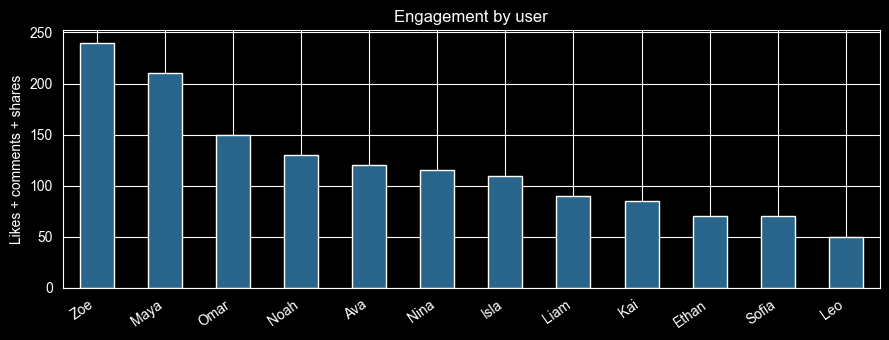

In [40]:
posts['Engagement'] = posts[['Likes', 'Comments', 'Shares']].sum(axis=1)
posts['EngagementRate'] = 100 * posts['Engagement'] / posts['Reach']

engagement_median = posts['Engagement'].median()
reach_median = posts['Reach'].median()
posts['AudienceType'] = 'Lower reach and engagement'
posts.loc[posts['Reach'].ge(reach_median), 'AudienceType'] = 'Additional marketing attention'
posts.loc[posts['Engagement'].ge(engagement_median), 'AudienceType'] = 'High engagement'

ranking = posts.sort_values('Engagement', ascending=False)
display(ranking[['User', 'Reach', 'Engagement', 'EngagementRate', 'Media', 'AudienceType']].round(2))

ax = ranking.set_index('User')['Engagement'].plot.bar(color='#29658a', figsize=(9, 3.5))
ax.set(title='Engagement by user', ylabel='Likes + comments + shares', xlabel='')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()

Zoe received the most engagement (240 interactions), followed by Maya (210) and Omar (150).

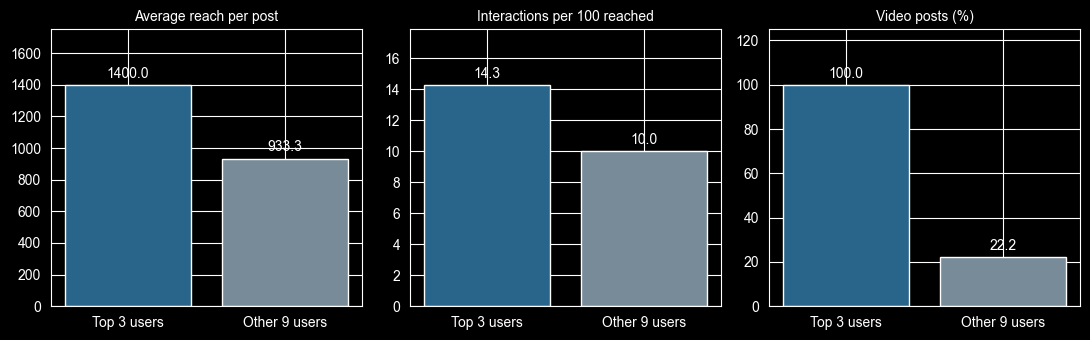

In [41]:
top_users = ranking.head(3)
other_users = ranking.iloc[3:]

comparison = pd.DataFrame({
    'Average reach per post': [top_users['Reach'].mean(), other_users['Reach'].mean()],
    'Interactions per 100 reached': [
        100 * top_users['Engagement'].sum() / top_users['Reach'].sum(),
        100 * other_users['Engagement'].sum() / other_users['Reach'].sum()
    ],
    'Video posts (%)': [
        100 * top_users['Media'].eq('Video').mean(),
        100 * other_users['Media'].eq('Video').mean()
    ]
}, index=['Top 3 users', 'Other 9 users'])

display(top_users[['User', 'Platform', 'Media', 'Reach', 'Engagement', 'EngagementRate']].round(2))
display(comparison.round(2))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for ax, metric in zip(axes, comparison.columns):
    bars = ax.bar(comparison.index, comparison[metric], color=['#29658a', '#778c98'])
    ax.bar_label(bars, fmt='%.1f', padding=3)
    ax.set_title(metric, fontsize=10)
    ax.set_ylim(0, comparison[metric].max() * 1.25)
fig.tight_layout()

**Greater exposure and more interactions relative to reach.** The three leaders averaged 1,400 accounts reached per post, compared with about 933 for the other users. They also received 14.29 interactions per 100 reported accounts reached, compared with 10.00 for the rest. This suggests the leaders benefited from reaching more people and getting more interaction relative to that reach.

**Video is a possible factor.** Zoe, Maya, and Omar all posted videos, compared with two of the other nine users.

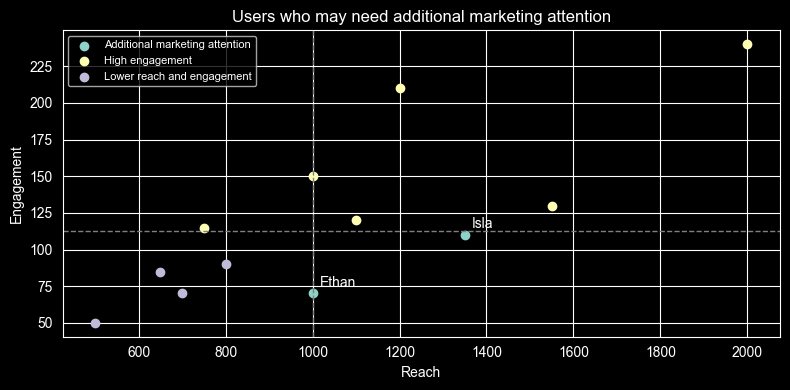

In [42]:
fig, ax = plt.subplots(figsize=(8, 4))
for audience_type, group in posts.groupby('AudienceType'):
    ax.scatter(group['Reach'], group['Engagement'], label=audience_type)
    if audience_type == 'Additional marketing attention':
        for row in group.itertuples():
            ax.annotate(row.User, (row.Reach, row.Engagement), xytext=(5, 5), textcoords='offset points')
ax.axhline(engagement_median, color='gray', linestyle='--', linewidth=1)
ax.axvline(reach_median, color='gray', linestyle='--', linewidth=1)
ax.set(title='Users who may need additional marketing attention', xlabel='Reach', ylabel='Engagement')
ax.legend(loc='upper left', fontsize=8)
fig.tight_layout()

**Additional attention.** Isla’s post reached 1,350 accounts and received 110 interactions. Ethan’s post reached 1,000 accounts and received 70 interactions. Both reached at least 1,000 accounts, the median reach, but received fewer than 112.5 interactions, the median engagement. Urban Fashion should review Isla’s post to understand why it drew fewer interactions despite its reach. For Ethan, there is a specific issue to follow up on. His post says the advertised size was unavailable, so the brand could confirm what is in stock or suggest an alternative.

## 4. Text analytics


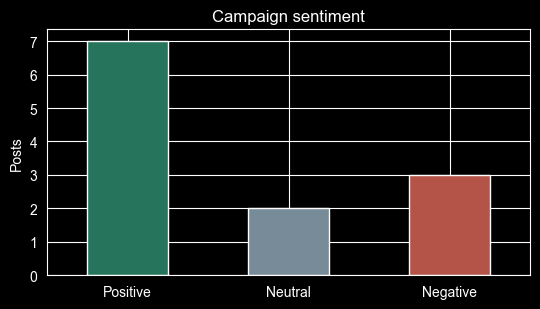

In [43]:
positive_words = {'love', 'great', 'excellent'}
negative_words = {'disappointed', 'frustrated', 'awful'}

def sentiment_score(post):
    words = post.lower().replace('.', ' ').replace('!', ' ').split()
    return sum(word in positive_words for word in words) - sum(word in negative_words for word in words)

posts['SentimentScore'] = posts['Post'].apply(sentiment_score)
posts['Sentiment'] = posts['SentimentScore'].apply(
    lambda score: 'Positive' if score > 0 else 'Negative' if score < 0 else 'Neutral'
)
sentiment_counts = posts['Sentiment'].value_counts().reindex(['Positive', 'Neutral', 'Negative'])
display(pd.DataFrame({'Posts': sentiment_counts, 'Percent': (100 * sentiment_counts / len(posts)).round(1)}))
display(posts.loc[posts['Sentiment'].eq('Negative'), ['User', 'Post']])
ax = sentiment_counts.plot.bar(color=['#26745c', '#778c98', '#b45448'], figsize=(5.5, 3.2))
ax.set(title='Campaign sentiment', ylabel='Posts', xlabel='')
plt.xticks(rotation=0)
plt.tight_layout()

**Campaign view:** Seven of 12 posts (58.3%) are positive, three are negative, and two are neutral. The positive posts support another campaign in this exercise, especially messaging about fit, styling, and value.

**Risks:** Two posts mention unavailable sizes and one mentions late delivery. Repeated stock complaints could reduce trust in advertised offers, and delivery delays could discourage repeat purchases.

**Improvements:** Show the sizes currently in stock, update sold-out ads quickly, and set clearer delivery expectations.

## 5. Location analytics


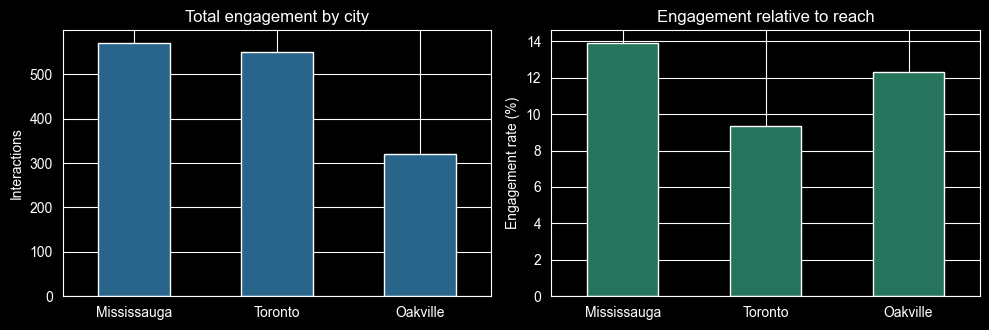

In [44]:
regions = posts.groupby('City').agg(Reach=('Reach', 'sum'), Engagement=('Engagement', 'sum'))
regions['EngagementRate'] = 100 * regions['Engagement'] / regions['Reach']
regions = regions.sort_values('Engagement', ascending=False)
display(regions.round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
regions['Engagement'].plot.bar(ax=axes[0], color='#29658a', title='Total engagement by city')
regions['EngagementRate'].plot.bar(ax=axes[1], color='#26745c', title='Engagement relative to reach')
axes[0].set(ylabel='Interactions', xlabel='')
axes[1].set(ylabel='Engagement rate (%)', xlabel='')
for ax in axes:
    ax.tick_params(axis='x', labelrotation=0)
fig.tight_layout()

**Highest engagement.** Mississauga leads in total engagement with 570 interactions. Toronto follows with 550 and had the largest summed reach.

**Where to invest.** I will recommend additional marketing in Oakville. Its reach is the lowest, yet it produced 320 interactions from 2,600 summed reach (12.31%), close to Mississauga's 13.90%.

**Why results might differ.** Toronto's greater exposure can help explain its high total. Content mix and customer experiences may also affect the response. With four posts per city, these comparisons are best used to choose a pilot.

## 6. Network analytics


In [45]:
connections = pd.DataFrame([
    ('Maya', 'Omar'), ('Maya', 'Ethan'), ('Maya', 'Sofia'), ('Omar', 'Sofia'),
    ('Zoe', 'Noah'), ('Zoe', 'Ava'), ('Zoe', 'Leo'), ('Noah', 'Ava'),
    ('Nina', 'Kai'), ('Nina', 'Isla'), ('Nina', 'Liam'), ('Isla', 'Kai')
], columns=['Source', 'Target'])

display(connections)

,Source,Target
0,Maya,Omar
1,Maya,Ethan
2,Maya,Sofia
3,Omar,Sofia
4,Zoe,Noah
5,Zoe,Ava
6,Zoe,Leo
7,Noah,Ava
8,Nina,Kai
9,Nina,Isla


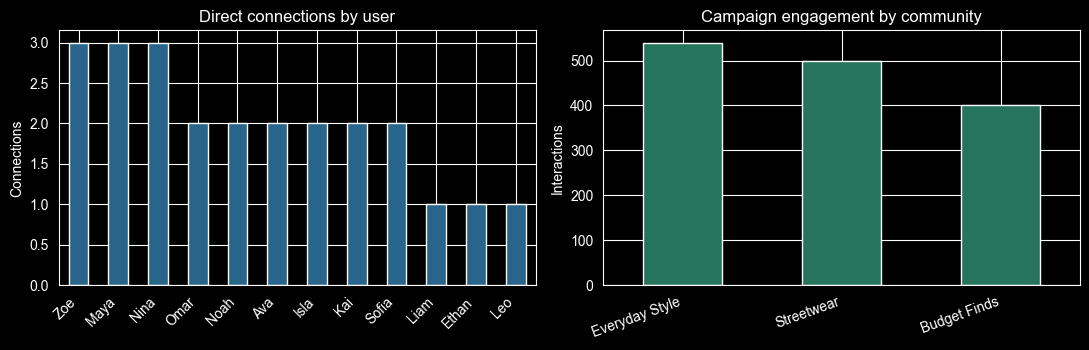

In [46]:
endpoints = pd.concat([connections['Source'], connections['Target']], ignore_index=True)
network = posts[['User', 'Community', 'Engagement']].copy()
network['DirectConnections'] = network['User'].map(endpoints.value_counts()).fillna(0).astype(int)
network['DegreeCentrality'] = network['DirectConnections'] / (len(network) - 1)
network = network.sort_values(['DirectConnections', 'Engagement'], ascending=False)

communities = network.groupby('Community')['Engagement'].sum().sort_values(ascending=False)
display(network.round(3))
display(communities.to_frame('Total engagement'))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
network.set_index('User')['DirectConnections'].plot.bar(ax=axes[0], color='#29658a')
axes[0].set(title='Direct connections by user', xlabel='', ylabel='Connections')
communities.plot.bar(ax=axes[1], color='#26745c')
axes[1].set(title='Campaign engagement by community', xlabel='', ylabel='Interactions')
plt.setp(axes[0].get_xticklabels(), rotation=45, ha='right')
plt.setp(axes[1].get_xticklabels(), rotation=20, ha='right')
fig.tight_layout()

**Influential users and communities.** Maya, Zoe, and Nina each have three direct connections, the highest in the sample. Each is connected to every other member of their four-person community. Everyday Style generated the most engagement (540 interactions), ahead of Streetwear (500) and Budget Finds (400).

**Value and collaboration.** Connected users can help a campaign reach people in their communities and surface feedback. Invite Maya to create a streetwear styling clip and Zoe to demonstrate everyday looks. Nina's connections make her feedback valuable. Follow up privately about her delivery experience and use what you learn to improve the Budget Finds campaign.

## 7. Integration of all analytics

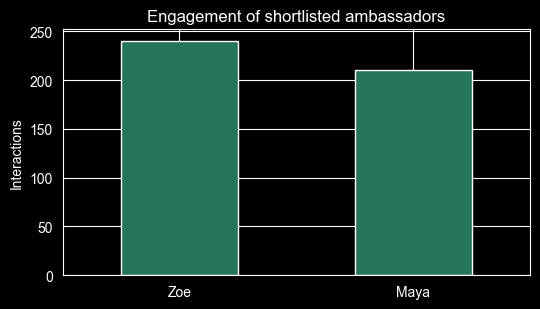

In [47]:
integrated = posts[['User', 'City', 'Community', 'Engagement', 'Sentiment']].merge(
    network[['User', 'DirectConnections', 'DegreeCentrality']],
    on='User'
)
community_max = integrated.groupby('Community')['DirectConnections'].transform('max')
integrated['HighValue'] = (
    integrated['Engagement'].ge(engagement_median)
    & integrated['Sentiment'].eq('Positive')
    & integrated['DirectConnections'].eq(community_max)
)
integrated = integrated.sort_values('Engagement', ascending=False)
display(integrated.round(3))
ambassadors = integrated.loc[integrated['HighValue'], ['User', 'Community', 'City', 'Engagement']]
display(ambassadors)

ax = ambassadors.set_index('User')['Engagement'].plot.bar(color='#26745c', figsize=(5.5, 3.2))
ax.set(title='Engagement of shortlisted ambassadors', xlabel='', ylabel='Interactions')
plt.xticks(rotation=0)
plt.tight_layout()

**Ambassador shortlist.** Zoe in Toronto and Maya in Mississauga meet all three criteria. Zoe brings the highest individual engagement and ties into the strongest community, Everyday Style. Maya is the top account in Streetwear by engagement and is based in Mississauga, the city with the most interactions. Nina is highly connected and clears the engagement threshold, but her negative post makes customer follow-up the better first step.


### Course materials used

- *Activity 6*, INFO57086, Sheridan College.
- Dr. Dipak Pudasaini, *Synthesizing Social Media Analytics Insights*, Chapter 7, Sheridan College.
- Course notebooks *Integration_of_Text_Network_Audience_Location_analytics.ipynb* and *analytics_report.ipynb*. These informed the four analysis types, user-level join, and business interpretation. The dataset and implementation above were created for this exercise.